# 05 · Decisions: using the Replacement Finder in summer 2022

The backtest (notebook 04) showed that the Finder beats simple scouting rules over 750 historical cases. Now we use it the way
a club would: for **real transfer decisions**.

We stand in **summer 2022**, at the end of FIFA 22. Three clubs have just lost an important midfielder:

| Club | Player leaving | What happened in reality |
|---|---|---|
| Brighton & Hove Albion | Yves Bissouma, defensive midfielder, 81 | Sold to Tottenham |
| Real Madrid | Casemiro, defensive midfielder, 89 | Sold to Manchester United |
| Brentford | Christian Eriksen, playmaker, 82 | Left on a free transfer to Manchester United |

For each one we ask the Finder for a shortlist, explain the choices and their risks, and finally make a recommendation.
The growth model is trained only on data known in summer 2022 (pairs up to FIFA 20 → 22).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))   # our own modules live in src/
import plot_style
from plot_style import BLUE, ORANGE, AQUA, INK_2, MUTED, EURO, euro

plot_style.apply()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from finder import ReplacementFinder, load_players

players = load_players()
finder = ReplacementFinder(players, decision_version=22)
season = finder.season
fifa23 = players[players.fifa_version == 23].set_index("player_id")   # for the reality check later

### Risk flags

A shortlist without risks is not an honest recommendation. For every candidate we add simple warning flags, each linked
to one of the pitfalls from the task:

- **bench player:** his club lists him as a substitute or reserve (`SUB`/`RES`). We have no minutes-played data, so this is
  our proxy for **"not enough playing time"**: his rating may rest on few matches, and he may not be used to starting.
- **weaker league:** his league is clearly weaker than the selling club's league. His rating may be less reliable (**different leagues**).
- **contract ending:** at most one year left. Good for the price, but the selling club may also lose him for free, so expect competition.
- **little growth left:** aged 27 or more, so the growth model expects him to stay level or decline (**uncertainty about the future**).

In [2]:
from finder import risk_flags   # the flags described above, shared with the app


def shortlist(name, club, budget, max_age=27, n=5, **options):
    """Show the sold player and the Finder's top-n replacements with risk flags."""
    sold = season[(season.short_name == name) & (season.club_name == club)].iloc[0]
    print(f"Selling {sold.short_name} ({sold.club_name}): {sold.main_position}, age {sold.age:.0f}, "
          f"rated {sold.overall:.0f}, value {euro(sold.value_eur)}, wage {euro(sold.wage_eur)}/week")
    print(f"Budget {euro(budget)}, wage cap {euro(sold.wage_eur)}/week, max age {max_age}")
    rec = finder.recommend(sold.player_id, budget=budget, n=n, wage_cap=sold.wage_eur, max_age=max_age,
                           min_overall=sold.overall - 12, **options)
    rec["risks"] = [risk_flags(r, sold) for _, r in rec.iterrows()]
    table = rec[["short_name", "age", "club_name", "league_name", "main_position", "overall",
                 "pred_overall_2y", "value_eur", "wage_eur", "fit", "risks"]].copy()
    table.columns = ["player", "age", "club", "league", "pos", "rating now", "predicted in 2y",
                     "value", "wage/week", "style match", "risks"]
    display(table.style.format({"age": "{:.0f}", "rating now": "{:.0f}", "predicted in 2y": "{:.1f}",
                                "value": euro, "wage/week": euro, "style match": "{:.2f}"}).hide(axis="index"))
    return sold, rec


def radar(players_rows, labels, title):
    """Compare players on the six summary stats."""
    stats = ["pace", "shooting", "passing", "dribbling", "defending", "physic"]
    angles = np.linspace(0, 2 * np.pi, len(stats), endpoint=False).tolist()
    fig, ax = plt.subplots(figsize=(5.5, 5.5), subplot_kw={"polar": True})
    for row, label, color in zip(players_rows, labels, [BLUE, ORANGE, AQUA]):
        values = row[stats].astype(float).tolist()
        ax.plot(angles + angles[:1], values + values[:1], color=color, lw=2, label=label)
        ax.fill(angles + angles[:1], values + values[:1], color=color, alpha=0.08)
    ax.set_xticks(angles, [s.capitalize() for s in stats])
    ax.set_ylim(30, 95)
    ax.set_title(title, pad=24)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1)
    plt.show()

## Case 1 · Brighton replaces Bissouma

Brighton is famous for buying cheaply, developing players and selling them high, which makes it a real Moneyball club.
Bissouma's FIFA value is €35.5M. We give the Finder a budget of **€25M** (about 70% of his value), his wage as the wage cap,
and a maximum age of 27 so the player still has resale value.

In [3]:
bissouma, rec_brighton = shortlist("Y. Bissouma", "Brighton & Hove Albion", budget=25e6)

Selling Y. Bissouma (Brighton & Hove Albion): CDM, age 24, rated 81, value €35.5M, wage €57K/week
Budget €25M, wage cap €57K/week, max age 27


player,age,club,league,pos,rating now,predicted in 2y,value,wage/week,style match,risks
N. Maksimović,26,Getafe,La Liga,CDM,79,79.0,€20.5M,€30K,0.61,-
J. Weigl,25,Benfica,Liga Portugal,CM,79,78.7,€23M,€16K,0.63,-
D. Sow,24,Eintracht Frankfurt,Bundesliga,CM,79,78.5,€24M,€29K,0.67,-
R. Tapia,25,Celta de Vigo,La Liga,CDM,79,78.4,€22M,€25K,0.60,bench player
P. Rosario,24,Nice,Ligue 1,CDM,78,77.8,€18.5M,€27K,0.79,-


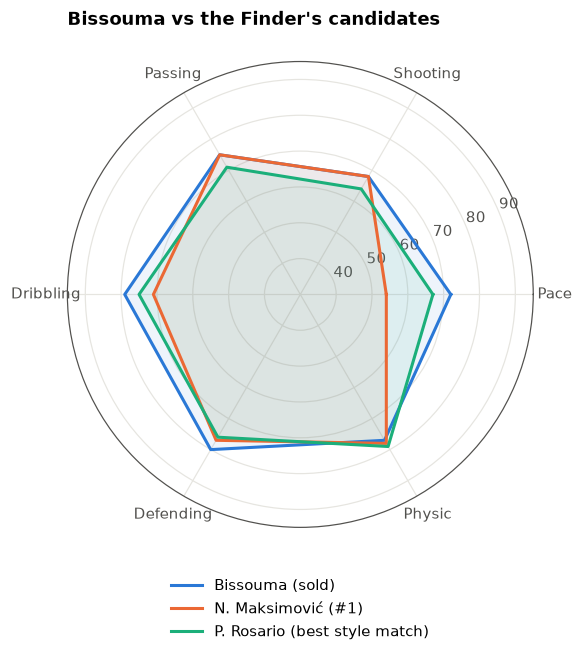

In [4]:
best_fit = rec_brighton.loc[rec_brighton.fit.idxmax()]
radar([bissouma, rec_brighton.iloc[0], best_fit],
      ["Bissouma (sold)", f"{rec_brighton.iloc[0].short_name} (#1)", f"{best_fit.short_name} (best style match)"],
      "Bissouma vs the Finder's candidates")

**What the Finder says.** All five candidates are rated 78–79, two or three points below Bissouma, and cost between about half
and two thirds of his value. None of them is expected to change much in two years. At 24–26 they're in their stable years,
which makes them **safer** buys than teenagers, but not bargains that will explode in value.

**Pablo Rosario** (Nice) stands out: the **best style match** (0.79), the **cheapest** of the five (€18.5M, leaving about €6.5M of
the budget), a regular starter, and four years of contract. The radar shows why the style match is high: Rosario's shape follows
Bissouma's on every axis, just slightly lower. The #1 pick, Maksimović, matches on passing and shooting but is much **slower**
(pace about 50 vs Bissouma's 72), a real difference for a team that presses high.

### What if the budget is 20% smaller?

In [5]:
smaller = finder.recommend(bissouma.player_id, budget=20e6, n=5, wage_cap=bissouma.wage_eur, max_age=27,
                           min_overall=bissouma.overall - 12)
smaller[["short_name", "age", "club_name", "overall", "pred_overall_2y", "value_eur", "fit"]].round(2)

,short_name,age,club_name,overall,pred_overall_2y,value_eur,fit
player_id,,,,,,,
235134,P. Rosario,24.0,Nice,78.0,77.79,18500000.0,0.79
230234,Everton Andrão,25.0,Fluminense,79.0,77.56,17000000.0,0.76
236499,Douglas Luiz,23.0,Aston Villa,77.0,77.34,20000000.0,0.74
247328,Unai Vencedor,20.0,Athletic Club,76.0,77.14,16500000.0,0.65
245630,Y. Fofana,22.0,Monaco,77.0,77.07,16000000.0,0.66


With €20M, **Rosario becomes the #1 choice**. He's the only player on both lists, so our recommendation doesn't depend on the
exact budget. The rest of the list becomes younger and cheaper. Note **Douglas Luiz** and **Unai Vencedor**: Vencedor was one of
the "predicted risers" from notebook 03, now reaching the top level.

### What did Brighton really do?

Brighton didn't buy a like-for-like replacement. In the data, its new midfielders in FIFA 23 are Billy Gilmour (rated 72,
€5M) and several teenagers. The real replacement came from inside: **Moisés Caicedo**, Brighton's own 20-year-old. The Finder
excludes a club's own players (you can't buy them), but we can ask what the growth model thought of him in summer 2022:

In [6]:
caicedo = season[(season.short_name == "M. Caicedo") & (season.club_name == "Brighton & Hove Albion")].iloc[0]
print(f"Caicedo, summer 2022: age {caicedo.age:.0f}, rated {caicedo.overall:.0f}, potential {caicedo.potential:.0f}, "
      f"value {euro(caicedo.value_eur)}")
print(f"Growth model prediction for summer 2024: {caicedo.pred_overall_2y:.1f}")
print(f"Actual rating in FIFA 23 (January 2023): {fifa23.loc[caicedo.player_id, 'overall']:.0f}")

Caicedo, summer 2022: age 19, rated 67, potential 79, value €2.4M
Growth model prediction for summer 2024: 70.7
Actual rating in FIFA 23 (January 2023): 73


The model expected Caicedo to grow by almost 4 points in two years. In reality he gained **6 points in half a season**. The
direction was right, but the model was far too cautious: truly exceptional development is the hardest thing to predict, because
the model learns from what *typical* players do. Still, a good use of the Finder for Brighton: **check your own squad first**.
A young player the growth model likes may already be the replacement.

## Case 2 · Real Madrid replaces Casemiro

This is the teacher's "сливочные" challenge. In reality Real bought **Aurélien Tchouaméni** from Monaco for a reported fee of
about €80M plus bonuses. Could half of that have bought a comparable player? Budget **€44M** (half of Casemiro's €88M FIFA value),
Casemiro's wage as the cap, maximum age 27.

In [7]:
casemiro, rec_real = shortlist("Casemiro", "Real Madrid", budget=44e6)

Selling Casemiro (Real Madrid): CDM, age 29, rated 89, value €88M, wage €310K/week
Budget €44M, wage cap €310K/week, max age 27


player,age,club,league,pos,rating now,predicted in 2y,value,wage/week,style match,risks
P. Højbjerg,25,Tottenham Hotspur,Premier League,CDM,83,82.1,€41M,€105K,0.75,-
D. Zakaria,24,Juventus,Serie A,CDM,81,82.0,€35.5M,€68K,0.56,-
M. Locatelli,23,Juventus,Serie A,CDM,82,81.6,€40M,€74K,0.68,-
Palhinha,25,Sporting CP,Liga Portugal,CDM,82,81.2,€36.5M,€18K,0.82,weaker league
Y. Bissouma,24,Brighton & Hove Albion,Premier League,CDM,81,81.1,€35.5M,€57K,0.72,bench player


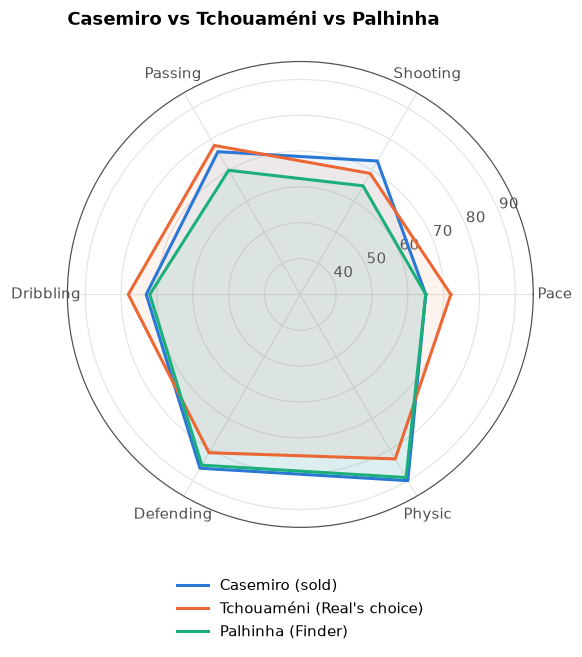

Tchouaméni, summer 2022: age 21, rated 81, FIFA value €52M, predicted in 2y: 82.0


In [8]:
tchouameni = season[season.short_name == "A. Tchouaméni"].iloc[0]
palhinha = rec_real[rec_real.short_name == "Palhinha"].iloc[0]
radar([casemiro, tchouameni, palhinha], ["Casemiro (sold)", "Tchouaméni (Real's choice)", "Palhinha (Finder)"],
      "Casemiro vs Tchouaméni vs Palhinha")
print(f"Tchouaméni, summer 2022: age {tchouameni.age:.0f}, rated {tchouameni.overall:.0f}, "
      f"FIFA value {euro(tchouameni.value_eur)}, predicted in 2y: {tchouameni.pred_overall_2y:.1f}")

**What the Finder says.** For half the money, it offers five players rated 81–83 **today**, as good as or better than Tchouaméni's
81 at the time. **Højbjerg** is the strongest now (83). **Palhinha** is the **best style match** (0.82) and earns a fraction of the
others' wages. The radar makes it visible: Palhinha's shape almost **lies on top of Casemiro's** (strong defending and physical
play), while Tchouaméni is a different, more ball-playing profile (better passing, dribbling and pace, less physical).

**Reality check: Fulham bought Palhinha in that same summer.** The FIFA 23 data shows him at Fulham. So the Finder's top style
match really was available, and a mid-table Premier League club could afford him. The list even contains **Bissouma** himself,
whom Tottenham bought that summer. (His "bench player" flag is misleading: Brighton had moved him to the reserves because he was
leaving. Flags are hints, not facts.) Palhinha's "weaker league" flag reminds us that Liga Portugal is a step below La Liga.

**But Tchouaméni isn't a bad decision either.** He was 21 with a potential of 88, and the growth model also expects him to improve.
Real paid for **future** quality and resale value, not only for the next season. The Finder answers "how do we replace Casemiro
cheaply?", while Real asked "who will be our midfielder for the next ten years?". Different questions lead to different answers.
That's a limitation of a single-season, single-role tool.

## Case 3 · Brentford replaces Eriksen

Eriksen left Brentford for free, so the club has little money to spend. Budget **€15M**, Eriksen's wage as the cap, maximum age 28.

In [9]:
eriksen, rec_brentford = shortlist("C. Eriksen", "Brentford", budget=15e6, max_age=28)

Selling C. Eriksen (Brentford): CM, age 29, rated 82, value €29.5M, wage €71K/week
Budget €15M, wage cap €71K/week, max age 28


player,age,club,league,pos,rating now,predicted in 2y,value,wage/week,style match,risks
J. Willock,21,Newcastle United,Premier League,CM,75,77.1,€12.5M,€26K,0.13,bench player
C. Jones,20,Liverpool,Premier League,CM,75,76.9,€12.5M,€57K,0.33,bench player
D. Frattesi,21,Sassuolo,Serie A,CM,75,76.8,€12.5M,€22K,0.26,-
G. Castrovilli,24,Fiorentina,Serie A,CM,77,76.8,€15M,€43K,0.19,bench player
Daniel Bragança,22,Sporting CP,Liga Portugal,CM,75,76.6,€12.5M,€11K,0.44,bench player


**Something is wrong here.** Look at the style match column: the values are very low. These are good young central midfielders,
but they're box-to-box players, **not playmakers**. Why didn't the style filter catch it?

In [10]:
pool = finder.candidates(eriksen.player_id, budget=15e6, wage_cap=eriksen.wage_eur, max_age=28,
                         min_overall=eriksen.overall - 12)
print(f"{len(pool)} candidates. Style match: median {pool.fit.median():.2f}, "
      f"top 10% above {pool.fit.quantile(0.9):.2f}")

686 candidates. Style match: median 0.10, top 10% above 0.64


Eriksen is a **rare player type**. For half of the candidates the style match is close to zero, so "keep the better half" still
keeps many players who play nothing like him. This is the case the **minimum style match** option was made for (tested in
notebook 04: about 3 points less success on average, but a closer copy of the sold player). Let's demand a match of at least 0.6:

In [11]:
eriksen, rec_brentford = shortlist("C. Eriksen", "Brentford", budget=15e6, max_age=28, min_fit=0.6)

Selling C. Eriksen (Brentford): CM, age 29, rated 82, value €29.5M, wage €71K/week
Budget €15M, wage cap €71K/week, max age 28


player,age,club,league,pos,rating now,predicted in 2y,value,wage/week,style match,risks
İ. Kahveci,25,Fenerbahçe,Super Lig,CAM,77,76.4,€14M,€45K,0.77,-
H. Elliott,18,Liverpool,Premier League,CAM,73,76.0,€7M,€23K,0.66,bench player
M. Lanzini,28,West Ham United,Premier League,CAM,78,75.9,€14M,€68K,0.67,little growth left
Denis Suárez,27,Celta de Vigo,La Liga,CM,78,75.9,€15M,€26K,0.84,little growth left
Óscar,23,Getafe,La Liga,CM,75,75.9,€12.5M,€21K,0.83,"bench player, contract ending"


Now the list makes sense: **creative midfielders** who pass, dribble and shoot from distance. Kahveci, Harvey Elliott, Lanzini,
Denis Suárez and Óscar are all style matches of about 0.66 or more.

**Lesson:** the tool is not a black box that is always right. A football expert must look at the result and adjust the settings.
Here the style match column made the problem visible immediately. That's why the Finder always shows *why* it chose each player.

In reality, the data shows only one new central midfielder at Brentford in FIFA 23, 18-year-old Yehor Yarmoliuk, so Brentford
didn't replace Eriksen like-for-like.

## Early reality check: what happened half a season later?

FIFA 23's last update is from January 2023, half a season after our decisions. That's too early to judge the two-year predictions,
but we can check that nothing went badly wrong:

In [12]:
check = pd.concat([
    rec_brighton.assign(case="Brighton"), rec_real.assign(case="Real Madrid"), rec_brentford.assign(case="Brentford")
])
check["rating Jan 2023"] = check.player_id.map(fifa23.overall)
check["club Jan 2023"] = check.player_id.map(fifa23.club_name)
check["change"] = check["rating Jan 2023"] - check.overall
check[["case", "short_name", "club_name", "overall", "pred_overall_2y", "rating Jan 2023", "change", "club Jan 2023"]].round(1)

,case,short_name,club_name,overall,pred_overall_2y,rating Jan 2023,change,club Jan 2023
player_id,,,,,,,,
239433,Brighton,N. Maksimović,Getafe,79.0,79.0,79.0,0.0,Getafe
222028,Brighton,J. Weigl,Benfica,79.0,78.7,79.0,0.0,Borussia Mönchengladbach
229752,Brighton,D. Sow,Eintracht Frankfurt,79.0,78.5,80.0,1.0,Eintracht Frankfurt
220673,Brighton,R. Tapia,Celta de Vigo,79.0,78.4,79.0,0.0,Celta de Vigo
235134,Brighton,P. Rosario,Nice,78.0,77.8,76.0,-2.0,Nice
213648,Real Madrid,P. Højbjerg,Tottenham Hotspur,83.0,82.1,84.0,1.0,Tottenham Hotspur
229261,Real Madrid,D. Zakaria,Juventus,81.0,82.0,81.0,0.0,Chelsea
222077,Real Madrid,M. Locatelli,Juventus,82.0,81.6,82.0,0.0,Juventus
229391,Real Madrid,Palhinha,Sporting CP,82.0,81.2,81.0,-1.0,Fulham


Half a season later, almost every shortlisted player is within a point or two of his summer rating, as expected for players in
their stable years. None collapsed. Several moved clubs (Weigl, Zakaria, Palhinha, Bissouma, Óscar), which confirms they were
really on the market.

One honest warning: **Rosario, our top recommendation for Brighton, dropped 2 points**, the biggest fall on the list, while Sow
gained one. Half a season is too short to judge, but it's a reminder that every prediction carries uncertainty. A proper check of
the two-year predictions needs FIFA 24 data, which isn't in our dataset.

## Our recommendation

**For Brighton (main case): sign Pablo Rosario from Nice, about €18.5M.**

- **Why him:** the best style match to Bissouma among all affordable candidates, a regular starter in a top-5 league, rated 78,
  with four years of contract. He stays on the shortlist (in fact becomes #1) if the budget is cut by 20%, so the choice is robust.
- **Why not the alternatives:** Djibril Sow (Frankfurt) is one point better now but a weaker style match and uses the whole budget.
  Renato Tapia (Celta) is a bench player at his club. Maksimović and Weigl are good, but less similar in style.
- **What it saves:** about €6.5M of the €25M budget, plus the €35.5M from selling Bissouma.
- **Remaining risks:** he's a few points below Bissouma today and isn't expected to grow (age 24, stable). By January 2023 his
  rating had dropped 2 points, so this risk is real. EA's value is not the real transfer fee, and Nice may ask more. **Plan B:**
  Djibril Sow, who had improved by then. As a parallel step, give Moisés Caicedo minutes: the growth model rates him highly.

**For Real Madrid:** if the goal is "replace Casemiro now for half the money", **Palhinha** or **Højbjerg** would have done it.
If the goal is "the midfielder for the next decade", paying for Tchouaméni's youth and potential is defensible. Our tool answers
the first question.

**For Brentford:** with a minimum style match, **Denis Suárez** (best style match, regular starter, €15M) or **İrfan Kahveci**
(€14M) are realistic creative replacements. Harvey Elliott fits well on paper, but Liverpool would never sell a young first-team
talent at his FIFA value, a good example of why EA prices aren't real prices.

## What could go wrong: limitations we must be honest about

| Limitation | How it affects our recommendation |
|---|---|
| Ratings and values come from EA, not from matches or real fees | Real fees are usually higher (Tchouaméni: FIFA €52M, real ~€80M+); the shortlist is a starting point for human scouts, not a final answer |
| No minutes-played data | We use "bench player" as a proxy; ratings of bench players may be less reliable |
| Different leagues | We flag weaker leagues; the growth model uses league strength, but ratings across leagues aren't perfectly comparable |
| The growth model is slightly optimistic in recent years | Predicted ratings are about 0.5–1 point too high; the order of candidates is unaffected |
| Players who disappear | Handled in the backtest (counted as failures), but the Finder can't predict injuries or personal issues |
| Rare player types | The default style filter can fail (Eriksen); the user must check the style match and tighten the filter |
| One role, one season | The tool replaces one player; it doesn't plan the whole squad or the club's long-term strategy (Tchouaméni case) |

## Summary

| Case | Recommendation | Price vs sold player | Key reason | Main risk |
|---|---|---|---|---|
| Brighton (Bissouma) | Pablo Rosario (plan B: Djibril Sow) | ~52% of his value | Best style match, starter, robust to budget cuts | Slightly lower level; dropped 2 points by Jan 2023 |
| Real Madrid (Casemiro) | Palhinha or Højbjerg | ~41–47% of his value | Rated 82–83 now; Palhinha's style is closest; Fulham really bought him that summer | Older than Tchouaméni, less resale value |
| Brentford (Eriksen) | Denis Suárez or Kahveci (with min. style match 0.6) | ~47–51% of his value | Real creative midfielders | Default filter failed for a rare profile; needed expert adjustment |